# Which facet matches carry useful lift?

Offline X-learner experiment, option 1. Same 293 reviewed pairs across 45 targets, Barbara only. Outcome: grade 1/2 = peer, grade 0 = non-peer.

This estimates adjusted **associations within selected candidates**, not identified causal CATE or valuation uplift. A high predicted lift does not imply high absolute comp quality. The two sources have different contrasts and evidence populations; do not compare their numerical effects as if they were the same treatment.

B3 uses per-facet 50/50 embedding and TF-IDF similarity from the same Sonnet profile condition as the saved agent run. Agent features are cited 0–100 pair ratings. Agent business model and B3 offering description are distinct. Overall agent grade, S, E, total B3, rank and human notes are excluded from predictors.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
# Pinned analysis: change only to another completed run you intend to inspect.
RUN = ROOT / "outputs-local/v1/facet_uplift/20261113T190330202875Z"
manifest = json.loads((RUN / "manifest.json").read_text())
features = pd.read_csv(RUN / "pair_features.csv")
effects = pd.read_csv(RUN / "oof_effects.csv")
summary = pd.read_csv(RUN / "facet_summary.csv")
folds = pd.read_csv(RUN / "fold_diagnostics.csv")
print(f"{manifest['pairs']} pairs, {manifest['targets']} targets. Source commit: {manifest['commit'][:8]}")
display(features.score_barbara.value_counts().sort_index().rename("Human labels"))

293 pairs, 45 targets. Source commit: 44727659


score_barbara
0     91
1    178
2     24
Name: Human labels, dtype: int64

## Flow and declared comparisons

For each source and facet: define strong/weak match → hold out whole targets → fit treated/control peer probability models → impute pseudo-effects with three inner target folds → fit ridge effect models → combine using estimated propensity → predict held-out effects.

Primary B3 treatment: above training median vs at/below. Sensitivity: upper vs lower third, omit middle. Primary agent treatment: 75/100 vs 0/25/50; sensitivity: 75/100 vs 0/25. Unknown is never a mismatch.

Other-facet values are imputed and scaled inside each fit. At least 15 rows across 5 targets per training arm are required. Sparse facets remain visible as partial or unsupported. See `v1/FACET_UPLIFT.md` for fixed settings and model equations.

,signal,missing_fraction
0,agent__primary_products,0.293515
1,agent__primary_services,0.515358
2,agent__customer_segment,0.245734
3,agent__end_markets,0.201365
4,agent__business_model,0.047782
5,agent__revenue_model,0.877133
6,agent__value_chain_position,0.245734
7,agent__geography_served,0.542662
8,agent__specialization,0.399317
9,agent__distribution_channels,0.843003


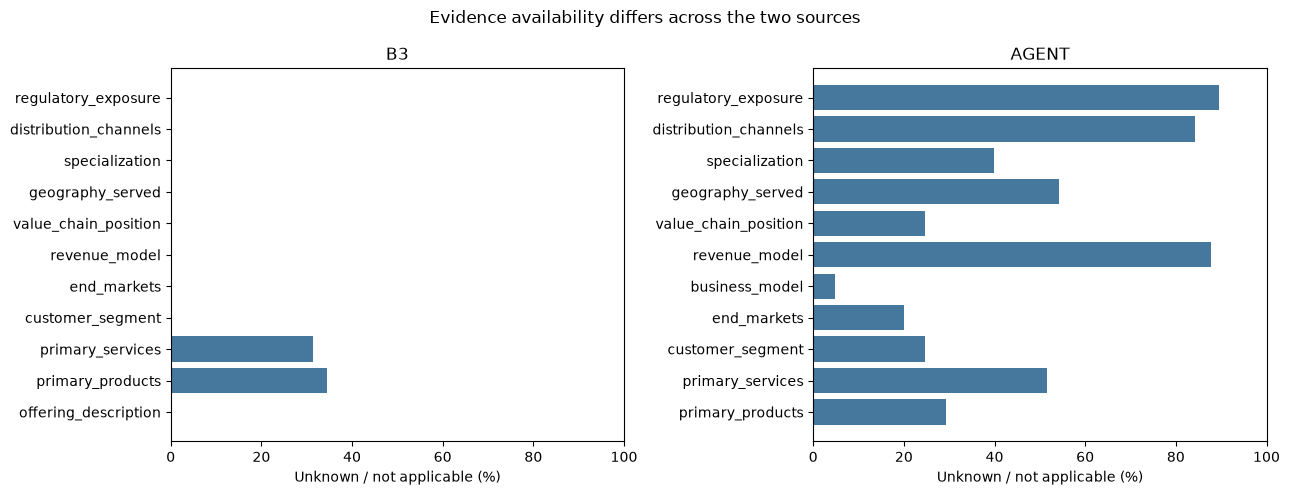

In [2]:
missing = features.filter(regex="^(b3|agent)__").isna().mean().rename("missing_fraction").rename_axis("signal").reset_index()
display(missing)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, source in zip(axes, ["b3", "agent"]):
    m = missing[missing.signal.str.startswith(source + "__")].copy()
    ax.barh(m.signal.str.split("__").str[1], 100*m.missing_fraction, color="#46789d")
    ax.set(title=source.upper(), xlabel="Unknown / not applicable (%)", xlim=(0, 100))
fig.suptitle("Evidence availability differs across the two sources")
fig.tight_layout()
fig.savefig(RUN / "missingness.png", dpi=160, bbox_inches="tight")
plt.show()

## Held-out estimates and support

The figure shows primary estimates only. Each estimate averages retained pairs within target, then averages targets. Only propensities from 0.1 to 0.9 are summarized. Intervals bootstrap targets **holding predictions fixed**; they omit refitting, reviewer, threshold and selection uncertainty and are not full CATE confidence intervals. No multiple-testing correction is applied. Interpret signs and threshold sensitivity as hypotheses, not significance or proof of a best facet.

Partial results can represent only a subset of target folds. Missing effects are not zero.

,source,facet,status,folds_ok,predicted_pairs,overlap_pairs,overlap_targets,mean_uplift,uplift_ci_low,uplift_ci_high
1,agent,business_model,complete,5,279,156.0,40.0,0.082759,0.033173,0.127792
3,agent,customer_segment,complete,5,221,125.0,39.0,0.089315,0.015741,0.168099
5,agent,distribution_channels,partial_or_unsupported,0,0,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,complete,5,234,123.0,39.0,0.107232,0.058825,0.148766
9,agent,geography_served,complete,5,134,117.0,35.0,0.089832,0.035866,0.140353
11,agent,primary_products,partial_or_unsupported,4,179,41.0,18.0,0.015799,-0.032801,0.056654
13,agent,primary_services,partial_or_unsupported,3,77,25.0,9.0,-0.002141,-0.035921,0.033337
15,agent,regulatory_exposure,partial_or_unsupported,0,0,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,partial_or_unsupported,0,0,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,partial_or_unsupported,0,0,NaN,NaN,NaN,NaN,NaN


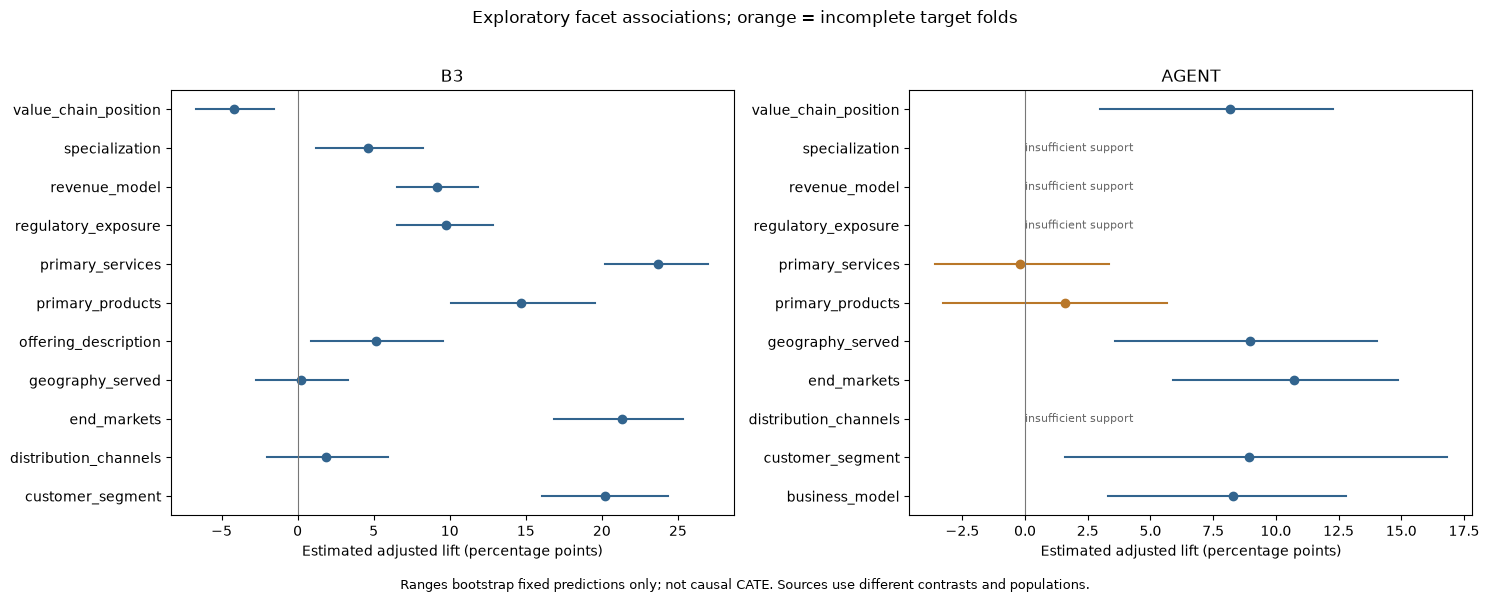

In [3]:
primary = summary[summary.rule.eq("primary")].copy()
display(primary[["source", "facet", "status", "folds_ok", "predicted_pairs", "overlap_pairs", "overlap_targets", "mean_uplift", "uplift_ci_low", "uplift_ci_high"]])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, source in zip(axes, ["b3", "agent"]):
    part = primary[primary.source.eq(source)].sort_values("facet").reset_index(drop=True)
    for i, row in part.iterrows():
        if pd.notna(row.mean_uplift):
            color = "#32648e" if row.status == "complete" else "#b97729"
            ax.plot([100*row.uplift_ci_low, 100*row.uplift_ci_high], [i, i], color=color)
            ax.scatter(100*row.mean_uplift, i, color=color)
        else:
            ax.text(0, i, "insufficient support", va="center", fontsize=8, color="#666666")
    ax.set_yticks(range(len(part)), part.facet)
    ax.axvline(0, color="#777777", linewidth=.8)
    ax.set(title=source.upper(), xlabel="Estimated adjusted lift (percentage points)")
fig.suptitle("Exploratory facet associations; orange = incomplete target folds")
fig.text(.5, .015, "Ranges bootstrap fixed predictions only; not causal CATE. Sources use different contrasts and populations.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, .04, 1, .96))
fig.savefig(RUN / "facet_lift.png", dpi=180, bbox_inches="tight")
plt.show()

## Does the answer depend on how we define a strong match?

The strict comparison changes the treatment contrast AND the eligible cohort, so changes are not purely estimator instability. Report both denominators. Neither rule was selected to maximize effects.

In [4]:
sensitivity = summary.pivot(index=["source", "facet"], columns="rule", values=["mean_uplift", "predicted_pairs", "folds_ok", "overlap_pairs"])
display(sensitivity)
display(folds[~folds.status.eq("ok")][["source", "facet", "rule", "fold", "controls", "treated", "targets_arm_0", "targets_arm_1", "status"]])

mean_uplift           predicted_pairs          \
rule                             extreme   primary         extreme primary   
source facet                                                                 
agent  business_model           0.209158  0.082759           186.0   279.0   
       customer_segment         0.335843  0.089315           128.0   221.0   
       distribution_channels         NaN       NaN             0.0     0.0   
       end_markets              0.240742  0.107232           135.0   234.0   
       geography_served         0.262739  0.089832            86.0   134.0   
       primary_products         0.006027  0.015799           136.0   179.0   
       primary_services         0.065579 -0.002141            40.0    77.0   
       regulatory_exposure           NaN       NaN             0.0     0.0   
       revenue_model                 NaN       NaN             0.0     0.0   
       specialization                NaN       NaN             0.0     0.0   
       value_chain_position     0.200720  0.081636           153.0   221.0   
b3     customer_segment         0.199214  0.202266           193.0   293.0   
       distribution_channels   -0.012963  0.018868           195.0   293.0   
       end_markets              0.344788  0.213396           195.0   293.0   
       geography_served         0.016333  0.002199           202.0   293.0   
       offering_description     0.089718  0.051454           199.0   293.0   
       primary_products         0.247402  0.147071           130.0   192.0   
       primary_services         0.282844  0.236724           133.0   201.0   
       regulatory_exposure      0.092722  0.097702           202.0   293.0   
       revenue_model            0.160459  0.091594           197.0   293.0   
       specialization           0.071481  0.045951           199.0   293.0   
       value_chain_position    -0.082056 -0.042153           197.0   293.0   

                             folds_ok         overlap_pairs          
rule                          extreme primary       extreme primary  
source facet                                                         
agent  business_model             5.0     5.0         116.0   156.0  
       customer_segment           5.0     5.0          76.0   125.0  
       distribution_channels      0.0     0.0           NaN     NaN  
       end_markets                5.0     5.0         102.0   123.0  
       geography_served           5.0     5.0          77.0   117.0  
       primary_products           4.0     4.0          35.0    41.0  
       primary_services           3.0     3.0          14.0    25.0  
       regulatory_exposure        0.0     0.0           NaN     NaN  
       revenue_model              0.0     0.0           NaN     NaN  
       specialization             0.0     0.0           NaN     NaN  
       value_chain_position       5.0     5.0          99.0   130.0  
b3     customer_segment           5.0     5.0         157.0   280.0  
       distribution_channels      5.0     5.0         156.0   259.0  
       end_markets                5.0     5.0         176.0   274.0  
       geography_served           5.0     5.0         197.0   292.0  
       offering_description       5.0     5.0         152.0   240.0  
       primary_products           5.0     5.0         105.0   163.0  
       primary_services           5.0     5.0         100.0   174.0  
       regulatory_exposure        5.0     5.0         178.0   266.0  
       revenue_model              5.0     5.0         152.0   248.0  
       specialization             5.0     5.0         168.0   268.0  
       value_chain_position       5.0     5.0         150.0   261.0

,source,facet,rule,fold,controls,treated,targets_arm_0,targets_arm_1,status
111,agent,primary_products,primary,1,165,14,32,8,insufficient_support
116,agent,primary_products,extreme,1,122,14,32,8,insufficient_support
121,agent,primary_services,primary,1,86,14,23,8,insufficient_support
123,agent,primary_services,primary,3,105,14,24,6,insufficient_support
126,agent,primary_services,extreme,1,40,14,20,8,insufficient_support
128,agent,primary_services,extreme,3,58,14,21,6,insufficient_support
160,agent,revenue_model,primary,0,23,5,12,4,insufficient_support
161,agent,revenue_model,primary,1,24,7,14,5,insufficient_support
162,agent,revenue_model,primary,2,22,9,12,7,insufficient_support
163,agent,revenue_model,primary,3,22,7,13,6,insufficient_support


## Diagnostics, not an effect accuracy score

Brier loss and AUC evaluate held-out **response probability**, not whether a facet effect is correct. The baseline is a training-fold constant response probability. The DR pseudo-effect is an adjusted diagnostic built from estimated response and propensity models, not an observed causal label. Uplift bins have few independent targets and are descriptive.

No model has observed the true alternative outcome for the same pair. There is no causal ground truth, Qini validation from a randomized experiment, or untouched independent label set here. Some of these labels already guided prior pipeline development. Repeated comp companies can cross target folds.

In [5]:
display(primary[["source", "facet", "brier", "baseline_brier", "response_auc", "dr_adjusted_difference", "outside_probability_range"]])
bins = pd.read_csv(RUN / "uplift_bins.csv")
display(bins[bins.rule.eq("primary")])

,source,facet,brier,baseline_brier,response_auc,dr_adjusted_difference,outside_probability_range
1,agent,business_model,0.153289,0.213324,0.803032,0.030178,1.0
3,agent,customer_segment,0.135831,0.219749,0.864711,-0.030892,5.0
5,agent,distribution_channels,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,0.142936,0.213818,0.853150,0.107342,3.0
9,agent,geography_served,0.156313,0.210310,0.826991,0.066845,0.0
11,agent,primary_products,0.160535,0.212620,0.794549,0.046532,0.0
13,agent,primary_services,0.141278,0.210383,0.824830,0.013860,0.0
15,agent,regulatory_exposure,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,NaN,NaN,NaN,NaN,NaN


,source,facet,rule,bin,pairs,targets,predicted_uplift,dr_adjusted_difference
3,agent,business_model,primary,0,53,28,-0.126964,0.018613
4,agent,business_model,primary,1,52,29,0.103434,0.153846
5,agent,business_model,primary,2,51,28,0.272246,-0.236250
9,agent,customer_segment,primary,0,42,22,-0.229524,0.055388
10,agent,customer_segment,primary,1,41,23,0.113710,0.178277
11,agent,customer_segment,primary,2,42,23,0.338838,-0.338982
15,agent,end_markets,primary,0,41,21,-0.091434,0.015720
16,agent,end_markets,primary,1,41,24,0.150366,0.071863
17,agent,end_markets,primary,2,41,27,0.268691,0.167224
21,agent,geography_served,primary,0,39,19,-0.117089,-0.089285


## Reproduce and investigate

From the root, run `uv run python v1/scripts/facet_uplift.py`, then point RUN above at the newly printed folder. Each run preserves source hashes, fold thresholds/support, pair-level OOF predictions and exclusions. The embedding model must already be available locally; downloads and LLM calls are disabled.

Use these results to select concrete pairs for review and identify where new labels or evidence are needed. A next experiment would measure whether including a promising facet improves a frozen pipeline on new reviewer labels. Do not sum these effects into a new matching score or rank candidate comps by lift.